# 01 · Data cleaning & exploratory analysis

**Owner:** Allen
**Report section:** Introduction / data; Generalization (distribution shift)

**Goal.** Class balance, length distributions by class, duplicate and overlap checks, train vs. unlabeled vs. test shift (length, vocabulary, style), and whether light cleaning changes baseline AUROC.

Run with *Restart & Run All*. Set `QUICK = True` for a fast debug pass on the 2,000-row
starter file, `QUICK = False` for the numbers that go in the report. Every result uses the
shared split from `src.data.get_split()` (seed 42), so numbers are comparable across notebooks.

**Outputs:** `results/eda_summary.json`, `results/eda_style_by_set.csv`, `results/cleaning_comparison.csv`, `figures/eda_*.png`.

In [1]:
# --- setup: make `src/` importable from anywhere (repo root, notebooks/, Kaggle/Colab clone) ---
import sys, time
from pathlib import Path

ROOT = Path.cwd().resolve()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

QUICK = False  # True: 2,000-row starter file for fast debugging. False: full data (report numbers).

In [2]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import SEED, set_seed, RESULTS_DIR, FIGURES_DIR
from src.data import get_split, load_test, load_unlabeled, load_train, get_cv_folds, xy
from src.features import build_features
from src.models import make_model
from src.evaluate import (auroc, cross_val_auroc, plot_roc, savefig, log_result,
                          save_predictions, predict_proba1)

set_seed(SEED)
SUFFIX = "_quick" if QUICK else ""   # keeps QUICK-mode outputs separate from real ones
import json, re
import seaborn as sns
from src.data import clean_text, overlap_report
from src.features import StylometricFeatures, STYLO_FEATURES
sns.set_theme(style="whitegrid")

## 1. Load raw and cleaned data

In [3]:
raw_train = load_train(clean=False, drop=False, quick=QUICK)
train = load_train(clean=True, quick=QUICK)
unl = load_unlabeled()
test = load_test()
raw_unl = load_unlabeled(clean=False, drop=False, verbose=False)
raw_test = load_test(clean=False, verbose=False)

# How many texts does the light cleaning actually change?
changed = {name: int((df["text"].map(clean_text) != df["text"]).sum())
           for name, df in [("train", raw_train), ("unlabeled", raw_unl), ("test", raw_test)]}
print("texts modified by clean_text:", changed)
ex = raw_train[raw_train["text"].map(clean_text) != raw_train["text"]].head(3)
for t in ex["text"]:
    print("RAW  :", repr(t[:120])); print("CLEAN:", repr(clean_text(t)[:120])); print()

[train] raw=10000 empty=0 dup_rows=0 conflicting_label_rows=0 dropped=0 final=10000 (clean=False)


[train] raw=10000 empty=0 dup_rows=0 conflicting_label_rows=0 dropped=0 final=10000 (clean=True)


[unlabeled] raw=3000 empty=0 dup_rows=0 conflicting_label_rows=0 dropped=0 final=3000 (clean=True)


[test] raw=3000 empty=0 dup_rows=0 conflicting_label_rows=0 dropped=0 final=3000 (clean=True)


texts modified by clean_text: {'train': 14, 'unlabeled': 2, 'test': 4}


RAW  : 'Andrew Croft (the chief executive at Lloyd’s) has been strongly criticised by Britain\x92s financial watchdog, which warned'
CLEAN: 'Andrew Croft (the chief executive at Lloyd’s) has been strongly criticised by Britain’s financial watchdog, which warned'

RAW  : 'What an enviable list of voice-over stars. <br/><br/>What fun characters mouthing multi-language pseudo-meaninged gibber'
CLEAN: 'What an enviable list of voice-over stars. <br/><br/>What fun characters mouthing multi-language pseudo-meaninged gibber'

RAW  : 'Jacques Boyceau (1607 â€“ 1642) was a French organist and composer who became a monk of the Congregation of Saint-Maur i'
CLEAN: 'Jacques Boyceau (1607 – 1642) was a French organist and composer who became a monk of the Congregation of Saint-Maur in '



## 2. Class balance and length by class

label
human (0)    5000
AI (1)       5000
Name: count, dtype: int64


label            AI   human
chars count  5000.0  5000.0
      mean   1282.8  1239.0
      std     443.2   320.8
      min     331.0   399.0
      25%     933.8  1015.0
      50%    1278.0  1222.0
      75%    1596.2  1462.0
      max    2938.0  2250.0
words count  5000.0  5000.0
      mean    208.4   209.0
      std      69.5    55.1
      min      75.0    75.0
      25%     151.0   166.0
      50%     209.0   204.0
      75%     262.0   250.0
      max     350.0   350.0

PosixPath('/Users/allenlu/Desktop/aml/CS5785_GroupProject/figures/eda_class_balance_length.png')

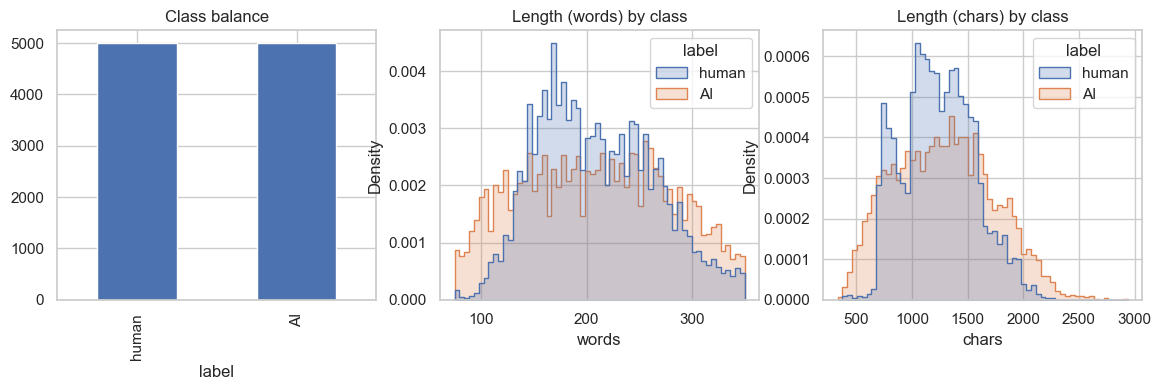

In [4]:
def lengths(df):
    return pd.DataFrame({"chars": df["text"].str.len(),
                         "words": df["text"].str.split().str.len()})

tr_len = lengths(train).assign(label=train["label"].map({0: "human", 1: "AI"}))
print(train["label"].value_counts().rename({0: "human (0)", 1: "AI (1)"}))
display(tr_len.groupby("label").describe().T.round(1))

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
train["label"].map({0: "human", 1: "AI"}).value_counts().plot.bar(ax=axes[0], title="Class balance")
for ax, col in zip(axes[1:], ["words", "chars"]):
    sns.histplot(tr_len, x=col, hue="label", bins=60, element="step", stat="density", ax=ax)
    ax.set_title(f"Length ({col}) by class")
savefig(fig, "eda_class_balance_length" + SUFFIX)

## 3. Duplicates and overlap between files

In [5]:
rep = train.attrs["cleaning_report"]
print(rep)
ov_clean = overlap_report(clean=True)
ov_raw = overlap_report(clean=False, verbose=False)
print("raw-text overlap train/test:", ov_raw["overlap_train_test"])

[train] raw=10000 empty=0 dup_rows=0 conflicting_label_rows=0 dropped=0 final=10000 (clean=True)


dup_rows_within_train            0
dup_rows_within_unlabeled        0
dup_rows_within_test             0
overlap_train_test               0
overlap_train_unlabeled          0
overlap_unlabeled_test           0
raw-text overlap train/test: 0


## 4. Train vs. unlabeled vs. test: length, vocabulary, style

,count,mean,std,min,25%,50%,75%,max
set,,,,,,,,
test,3000.0,217.0,61.0,75.0,173.0,213.0,262.0,350.0
train-AI,5000.0,208.4,69.5,75.0,151.0,209.0,262.0,350.0
train-human,5000.0,209.0,55.1,75.0,166.0,204.0,250.0,350.0
unlabeled,3000.0,210.3,65.5,75.0,158.0,206.5,258.0,350.0


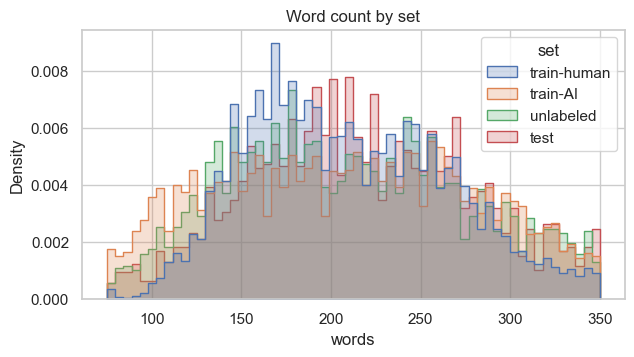

In [6]:
sets = {"train-human": train[train.label == 0], "train-AI": train[train.label == 1],
        "unlabeled": unl, "test": test}
len_df = pd.concat([lengths(d).assign(set=k) for k, d in sets.items()], ignore_index=True)

fig, ax = plt.subplots(figsize=(7, 3.5))
sns.histplot(len_df, x="words", hue="set", bins=60, element="step", stat="density", common_norm=False, ax=ax)
ax.set_title("Word count by set")
savefig(fig, "eda_length_by_set" + SUFFIX)
display(len_df.groupby("set")["words"].describe().round(1))

In [7]:
tok = re.compile(r"[a-z']+")
def vocab(df):
    from collections import Counter
    c = Counter()
    for t in df["text"]:
        c.update(tok.findall(t.lower()))
    return c

v_train, v_unl, v_test = vocab(train), vocab(unl), vocab(test)
def oov_rate(v_other, v_ref):
    total = sum(v_other.values())
    return sum(n for w, n in v_other.items() if w not in v_ref) / total

vocab_stats = {
    "vocab_size_train": len(v_train), "vocab_size_unlabeled": len(v_unl), "vocab_size_test": len(v_test),
    "oov_token_rate_unlabeled_vs_train": oov_rate(v_unl, v_train),
    "oov_token_rate_test_vs_train": oov_rate(v_test, v_train),
    "type_jaccard_train_test": len(set(v_train) & set(v_test)) / len(set(v_train) | set(v_test)),
}
vocab_stats

{'vocab_size_train': 65646,
 'vocab_size_unlabeled': 32621,
 'vocab_size_test': 37205,
 'oov_token_rate_unlabeled_vs_train': 0.023773681416158397,
 'oov_token_rate_test_vs_train': 0.03215880200905314,
 'type_jaccard_train_test': 0.3080376446648862}

In [8]:
# Mean stylometric features per set: big gaps between train and test mean distribution shift.
sty = StylometricFeatures()
style = pd.DataFrame({k: sty.transform(d["text"]).mean(axis=0) for k, d in sets.items()},
                     index=STYLO_FEATURES)
style["train (all)"] = sty.transform(train["text"]).mean(axis=0)
style["test / train ratio"] = style["test"] / style["train (all)"].replace(0, np.nan)
style.to_csv(RESULTS_DIR / f"eda_style_by_set{SUFFIX}.csv")
style.round(4)

,train-human,train-AI,unlabeled,test,train (all),test / train ratio
n_chars,1238.996216,1282.819580,1268.073975,1274.931641,1260.907959,1.0111
n_words,214.706604,212.787598,214.745300,220.324402,213.747101,1.0308
avg_word_len,4.668400,4.870600,4.784600,4.647800,4.769500,0.9745
n_sents,16.351601,14.860400,15.907300,18.259701,15.606000,1.1700
avg_sent_len,17.495600,23.683599,19.348400,18.609800,20.589500,0.9038
std_sent_len,8.525400,10.723800,8.798100,7.894900,9.624600,0.8203
type_token_ratio,0.589600,0.629200,0.598200,0.590400,0.609400,0.9688
comma_rate,0.045800,0.044600,0.046400,0.060500,0.045200,1.3377
semicolon_rate,0.001500,0.001300,0.001100,0.002300,0.001400,1.6178
colon_rate,0.001600,0.004000,0.002700,0.002200,0.002800,0.7739


## 5. Does light cleaning matter? Raw vs. cleaned baseline AUROC

Same split ids, same model; only the text preprocessing differs.

In [9]:
rows = []
for clean in (False, True):
    tr, va = get_split(quick=QUICK, clean=clean, drop=clean, verbose=False)
    m = make_model("baseline").fit(tr["text"], tr["label"])
    val_auc = auroc(va["label"], predict_proba1(m, va["text"]))
    cv = cross_val_auroc(make_model("baseline"), pd.concat([tr["text"], va["text"]]),
                         np.r_[tr["label"], va["label"]])
    rows.append({"clean": clean, "n_train": len(tr), "n_val": len(va), "val_auroc": val_auc,
                 "cv_auroc_mean": cv["cv_auroc_mean"], "cv_auroc_std": cv["cv_auroc_std"]})
    log_result("cleaning_comparison", {"clean": clean, "quick": QUICK, "model": "baseline"},
               {k: v for k, v in rows[-1].items() if k != "clean"})
cmp = pd.DataFrame(rows)
cmp

,clean,n_train,n_val,val_auroc,cv_auroc_mean,cv_auroc_std
0,False,8000,2000,0.956326,0.953939,0.001085
1,True,8000,2000,0.956313,0.953932,0.001084


In [10]:
summary = {"quick": QUICK, "cleaning_report": vars(rep), "texts_modified_by_cleaning": changed,
           "overlap_clean": ov_clean, "overlap_raw": ov_raw,
           **{k: float(v) if isinstance(v, float) else v for k, v in vocab_stats.items()}}
(RESULTS_DIR / f"eda_summary{SUFFIX}.json").write_text(json.dumps(summary, indent=2, default=str))
print(json.dumps(summary, indent=2, default=str))

{
  "quick": false,
  "cleaning_report": {
    "name": "train",
    "clean": true,
    "n_raw": 10000,
    "n_empty": 0,
    "n_duplicate_rows": 0,
    "n_conflicting_label_rows": 0,
    "n_dropped": 0,
    "n_final": 10000,
    "notes": []
  },
  "texts_modified_by_cleaning": {
    "train": 14,
    "unlabeled": 2,
    "test": 4
  },
  "overlap_clean": {
    "dup_rows_within_train": 0,
    "dup_rows_within_unlabeled": 0,
    "dup_rows_within_test": 0,
    "overlap_train_test": 0,
    "overlap_train_unlabeled": 0,
    "overlap_unlabeled_test": 0
  },
  "overlap_raw": {
    "dup_rows_within_train": 0,
    "dup_rows_within_unlabeled": 0,
    "dup_rows_within_test": 0,
    "overlap_train_test": 0,
    "overlap_train_unlabeled": 0,
    "overlap_unlabeled_test": 0
  },
  "vocab_size_train": 65646,
  "vocab_size_unlabeled": 32621,
  "vocab_size_test": 37205,
  "oov_token_rate_unlabeled_vs_train": 0.023773681416158397,
  "oov_token_rate_test_vs_train": 0.03215880200905314,
  "type_jaccard_trai

## Takeaways (fill in after running on full data)

* TODO: class balance / length differences between human and AI text
* TODO: duplicate and overlap counts, and what we did about them
* TODO: how different test looks from train (length, OOV rate, style table)
* TODO: whether cleaning changed AUROC